# Team 11 — Data Leakage: Correct Methodology

**Research question:** How can data leakage create misleadingly good ML results?

This notebook establishes a valid baseline for predicting bank term-deposit subscription **before a marketing call begins**. Therefore, `duration` is excluded because it is not yet known at that prediction time. The test set is kept separate, preprocessing is fitted through a pipeline on training data only, and the split is stratified.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
TEST_SIZE = 0.30


In [2]:
# Load bank-full.csv from the same folder as this notebook
# The UCI bank-full.csv file uses semicolon separators.
df = pd.read_csv("bank-full.csv", sep=";")

# Encode the target: yes = 1, no = 0
df["target"] = (df["y"] == "yes").astype(int)

print("Dataset shape:", df.shape)
print("Target distribution:")
print(df["y"].value_counts())
display(df.head())


Dataset shape: (41188, 22)
Target distribution:
y
no     36548
yes     4640
Name: count, dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,target
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0


In [3]:
# Shared, stratified split: preserve class proportions in train and test.
features = ["age", "job", "marital", "education", "housing", "loan", "poutcome"]
X = df[features].copy()
y = df["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))


Training rows: 28831
Test rows: 12357
Train positive rate: 0.1127
Test positive rate: 0.1126


## Preprocessing and model

The pipeline ensures the scaler and one-hot encoder are fitted on training data during `fit`, not on the test set. `stratify=y` keeps the target class proportions approximately stable.

In [4]:
def make_model(numeric_features, categorical_features):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        # Entropy-based Decision Tree; similar criterion to ID3, not a literal ID3 implementation.
        ("classifier", DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE))
    ])

def get_scores(y_true, y_pred, name):
    return {
        "Experiment": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    }


In [5]:
model_correct = make_model(
    numeric_features=["age"],
    categorical_features=["job", "marital", "education", "housing", "loan", "poutcome"]
)

model_correct.fit(X_train, y_train)
y_pred_correct = model_correct.predict(X_test)

correct_scores = get_scores(y_test, y_pred_correct, "Correct methodology")
print("CORRECT METHODOLOGY — CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_correct, target_names=["No", "Yes"], zero_division=0))
display(pd.DataFrame([correct_scores]).set_index("Experiment").round(4))


CORRECT METHODOLOGY — CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.90      0.96      0.93     10965
         Yes       0.34      0.17      0.23      1392

    accuracy                           0.87     12357
   macro avg       0.62      0.56      0.58     12357
weighted avg       0.84      0.87      0.85     12357



,Accuracy,Precision,Recall,F1-Score
Experiment,,,,
Correct methodology,0.8694,0.3414,0.1717,0.2285


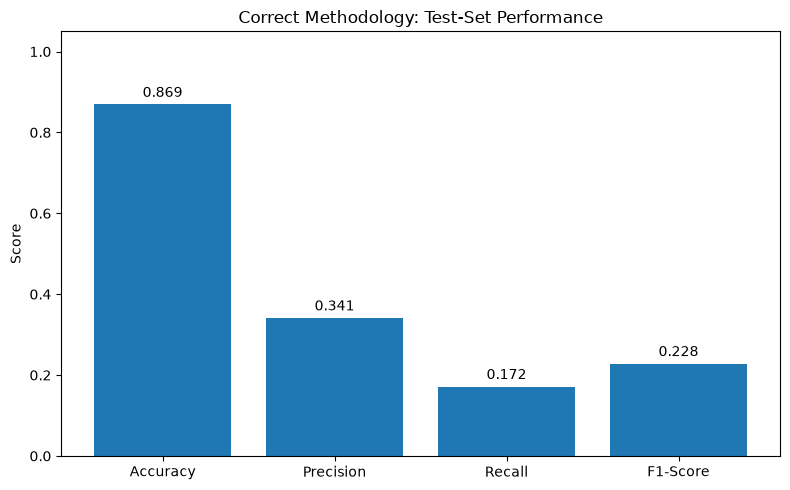

In [6]:
# Visualize the baseline metrics
metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
metric_values = [correct_scores[m] for m in metric_names]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.ylim(0, 1.05)
plt.title("Correct Methodology: Test-Set Performance")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


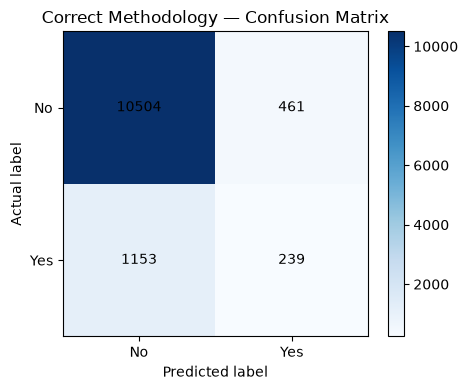

In [7]:
# Confusion matrix on the untouched test set
cm = confusion_matrix(y_test, y_pred_correct)
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Correct Methodology — Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], labels=["No", "Yes"])
ax.set_yticks([0, 1], labels=["No", "Yes"])
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()


## Interpretation guide

- These scores are the baseline for a model that predicts before a call starts.
- Accuracy alone may hide weak detection of the minority `yes` class, so inspect precision, recall, F1-score and the confusion matrix.
- The model is an entropy-based Decision Tree, not a literal implementation of the original ID3 algorithm.
- A single split has sampling variability; this experiment is evidence for the investigation, not a guarantee of future performance.